# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [2]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [9]:
# TASK 1: audit data quality.
print("\nDataset dimension:")
print(df_pe.shape)
print("\nMissing values:")
print(df_pe.isnull().sum())
print("\nNumber duplicates")
print(df_pe.duplicated().sum())
print("\nstatical summary:")
print(df_pe.describe())


Dataset dimension:
(6000, 15)

Missing values:
SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64

Number duplicates
0

statical summary:
       Max_Section_Entropy  Import_Count  Suspicious_API_Imports  \
count          6000.000000   5771.000000             6000.000000   
mean              5.709010     83.386866                2.800167   
std               1.170152     50.301130                3.094430   
min               2.146111      0.000000                0.000000   
25%               4.821742     41.184528         

np.int64(59)

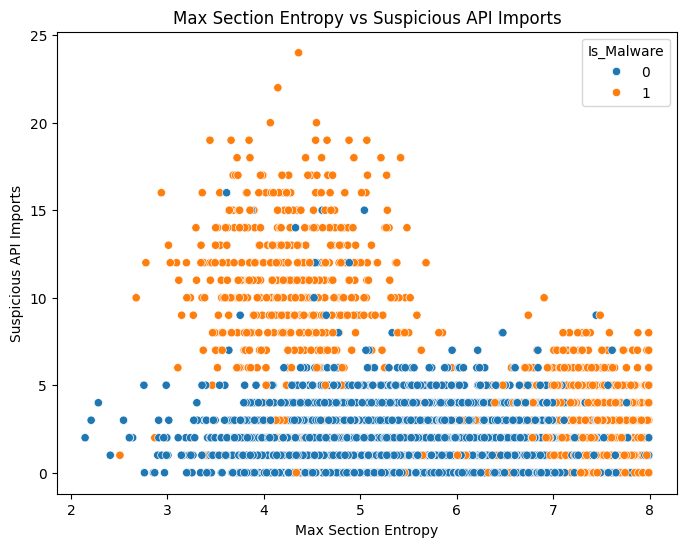

In [20]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
# count 99999.0 values; visualize Max_Section_Entropy vs Suspicious_API_Imports,
# using Is_Malware as the hue.
import matplotlib.pyplot as plt
import seaborn as sns
count =(df_pe["Virtual_to_Raw_Size_Ratio"]==99999.0).sum()
display(count)
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_pe,
    x="Max_Section_Entropy",
    y="Suspicious_API_Imports",
    hue="Is_Malware"
)
plt.title("Max Section Entropy vs Suspicious API Imports")
plt.xlabel("Max Section Entropy")
plt.ylabel("Suspicious API Imports")

plt.show()


In [23]:
# TASK 3: define the target and clean feature matrix.
# drop SHA256_File_ID, VT_PostScan_Detections and Is_Malware from X.
# replace impossible Virtual_to_Raw_Size_Ratio == 99999.0 with np.nan.
# Keep the target y separate.
y = df_pe["Is_Malware"]

X=df_pe.drop(
      columns=["SHA256_File_ID", "VT_PostScan_Detections", "Is_Malware"]
)

X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nMissing values in X:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

Shape of X: (6000, 12)
Shape of y: (6000,)

Missing values in X:
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio      59
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
dtype: int64

Target distribution:
Is_Malware
0    4389
1    1611
Name: count, dtype: int64


## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [26]:
# stratified development/test split.
# define pipelines using SimpleImputer(strategy="median").
# RobustScaler should be used for Logistic Regression only.
X_dev, X_test, y_dev, y_test = train_test_split( X,y,test_size=0.20,random_state=SEED,stratify=y)
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=SEED))
])
dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(max_depth=None, random_state=SEED))
])
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1
    ))
])
print("X_dev:", X_dev.shape)
print("X_test:", X_test.shape)
print("y_dev:", y_dev.shape)
print("y_test:", y_test.shape)

X_dev: (4800, 12)
X_test: (1200, 12)
y_dev: (4800,)
y_test: (1200,)


In [27]:
#  define StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)
#  define candidate models and evaluate using cross_validate.

models = {
    "Logistic Regression": lr_pipeline,
    "Deep Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline
}
# Suggested scoring: f1 and average_precision.

scoring = {
    "f1": "f1",
    "pr_auc": "average_precision"
}
# Record mean train F1, mean validation F1, validation PR-AUC and fit time.
results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean Train F1": scores["train_f1"].mean(),
        "Mean Validation F1": scores["test_f1"].mean(),
        "Validation PR-AUC": scores["test_pr_auc"].mean(),
        "Fit Time": scores["fit_time"].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean Validation F1",
    ascending=False
)

display(results_df.round(4))

Evaluating Logistic Regression...
Evaluating Deep Decision Tree...
Evaluating Random Forest...


,Model,Mean Train F1,Mean Validation F1,Validation PR-AUC,Fit Time
0,Logistic Regression,0.9231,0.9238,0.9080,0.0270
2,Random Forest,1.0000,0.9237,0.9049,2.2770
1,Deep Decision Tree,1.0000,0.8301,0.7330,0.0569


### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [28]:
# measure prediction latency for shortlisted fitted models.
# Use repeated batch predictions; report milliseconds per 1,000 files
# and document hardware/runtime limitations.
# Select shortlisted models
shortlisted_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

# Fit shortlisted models on the development set
for name, model in shortlisted_models.items():
    model.fit(X_dev, y_dev)
    import time
import numpy as np

# Select a batch of 1,000 files from the test set
X_batch = X_test.iloc[:1000]

# Number of repeated predictions
n_repeats = 100

latency_results = []

for name, model in shortlisted_models.items():

    # Warm-up prediction
    model.predict(X_batch)

    start_time = time.perf_counter()

    for _ in range(n_repeats):
        model.predict(X_batch)

    end_time = time.perf_counter()

    # Calculate average prediction time in milliseconds
    total_time = end_time - start_time

    latency_ms = (total_time / n_repeats) * 1000

    latency_results.append({
        "Model": name,
        "Latency (ms / 1000 files)": round(latency_ms, 4)
    })

latency_df = pd.DataFrame(latency_results)

display(latency_df)

,Model,Latency (ms / 1000 files)
0,Logistic Regression,1.9530
1,Random Forest,59.4167


## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [31]:
# fit shortlisted models on X_dev only, then predict probabilities on X_test.
# find and VERIFY a disagreement. Use threshold=0.50 for this diagnostic only.
# Never label a prediction "missed" or "caught" without checking y_true and y_pred.
shortlisted_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

probabilities = {}

for name, model in shortlisted_models.items():

    # Fit model on development set only
    model.fit(X_dev, y_dev)

    # Predict malware probabilities on test set
    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(f"{name}: fitted successfully.")

# 2. Convert probabilities into binary predictions
# Threshold 0.50 is used for this diagnostic only.

diagnostic_predictions = {}

for name, proba in probabilities.items():
    diagnostic_predictions[name] = (proba >= 0.50).astype(int)

# 3. Find a disagreement between shortlisted models

disagreement_indices = np.where(
    diagnostic_predictions["Logistic Regression"] !=
    diagnostic_predictions["Random Forest"]
)[0]

Logistic Regression: fitted successfully.
Random Forest: fitted successfully.


SHAP version: 0.54.1
Logistic Regression fitted successfully.
Random Forest fitted successfully.

Number of disagreements: 4

--- VERIFIED DISAGREEMENT ---
Test sample: 5787
Actual label: 1

Model: Logistic Regression
Predicted label: 0
Correct prediction: False

Model: Random Forest
Predicted label: 1
Correct prediction: True

Random Forest extracted successfully.
TreeExplainer created successfully.
SHAP values calculated successfully.


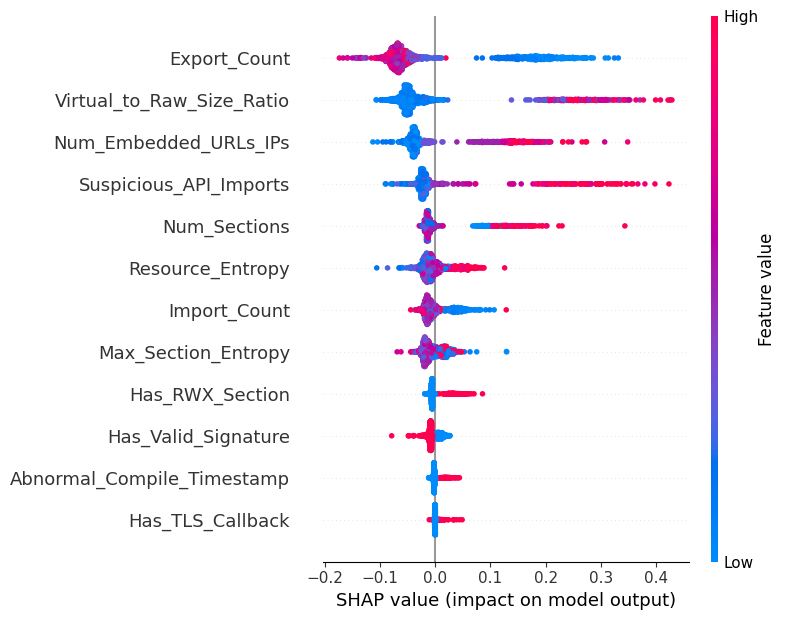


--- LOCAL SHAP EXPLANATION ---
Sample: 5787
Actual label: 1
Random Forest prediction: 1


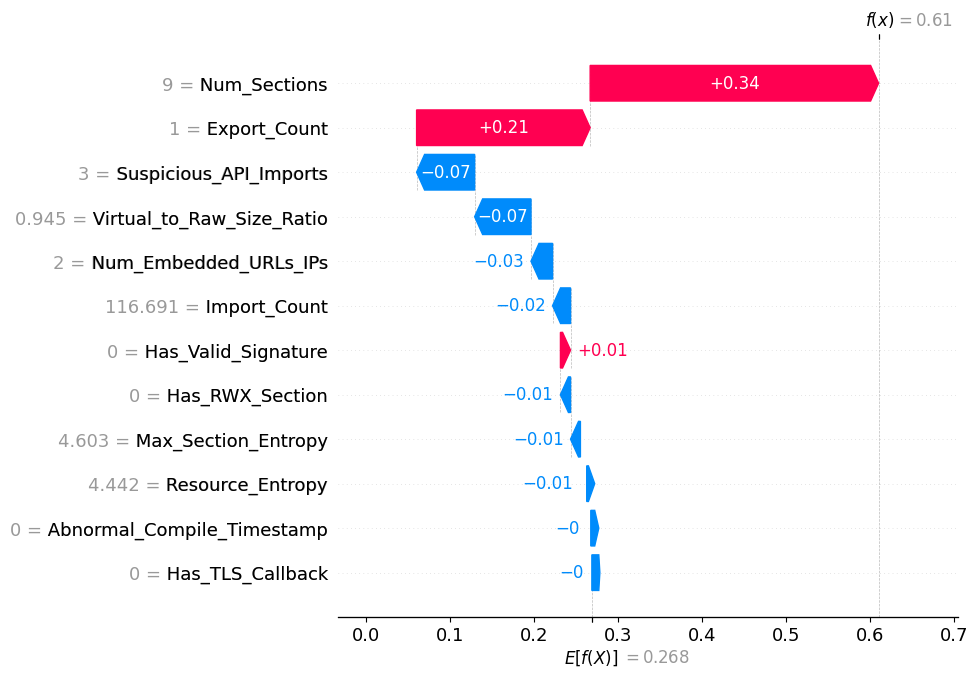

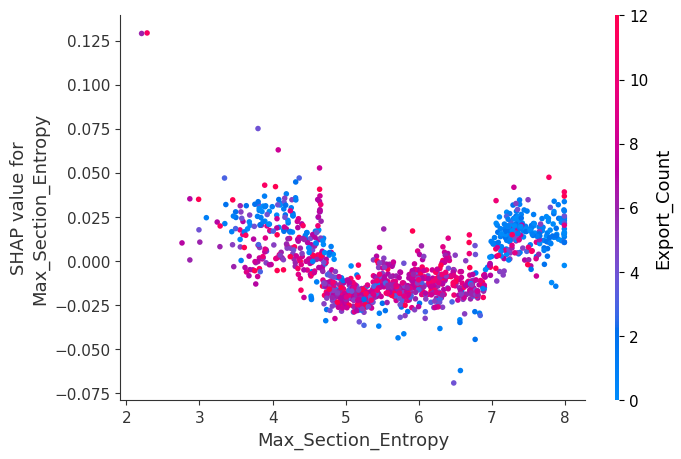


SHAP analysis completed successfully.


In [32]:
#  install/import shap if needed.
#  use shap.TreeExplainer with a supported fitted tree model.
#  produce global beeswarm and local waterfall for the verified case.
# 1. Install and import SHAP
%pip install -q shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

# 2. Fit shortlisted models on X_dev only
# This also makes the cell independent of previous fitting cells.

shortlisted_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

probabilities = {}

for name, model in shortlisted_models.items():

    model.fit(X_dev, y_dev)

    # Probability of class 1 (Malware)
    malware_index = list(model.classes_).index(1)

    probabilities[name] = model.predict_proba(X_test)[:, malware_index]

    print(name, "fitted successfully.")


# 3. Find disagreement between the two models
# Threshold 0.50: diagnostic only

diagnostic_predictions = {
    name: (proba >= 0.50).astype(int)
    for name, proba in probabilities.items()
}

disagreement_indices = np.where(
    diagnostic_predictions["Logistic Regression"] !=
    diagnostic_predictions["Random Forest"]
)[0]

print("\nNumber of disagreements:", len(disagreement_indices))

# 4. Verify the disagreement

if len(disagreement_indices) > 0:

    idx = disagreement_indices[0]

    y_true = int(y_test.iloc[idx])

    print("\n--- VERIFIED DISAGREEMENT ---")
    print("Test sample:", X_test.index[idx])
    print("Actual label:", y_true)

    for name, predictions in diagnostic_predictions.items():

        y_pred = int(predictions[idx])

        print("\nModel:", name)
        print("Predicted label:", y_pred)
        print("Correct prediction:", y_pred == y_true)

else:
    print("No disagreement found.")

# 5. Extract fitted Random Forest and preprocess data

rf_model = rf_pipeline.named_steps["model"]
imputer = rf_pipeline.named_steps["imputer"]

X_test_imputed = imputer.transform(X_test)

feature_names = X_test.columns.tolist()

X_test_shap = pd.DataFrame(
    X_test_imputed,
    columns=feature_names,
    index=X_test.index
)

print("\nRandom Forest extracted successfully.")

# 6. Create SHAP TreeExplainer

explainer = shap.TreeExplainer(rf_model)

print("TreeExplainer created successfully.")

# 7. Calculate SHAP values

shap_values = explainer.shap_values(X_test_shap)

# Support different SHAP output formats

if isinstance(shap_values, list):
    malware_shap_values = shap_values[1]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    malware_shap_values = shap_values[:, :, 1]

else:
    malware_shap_values = shap_values

print("SHAP values calculated successfully.")

# 8. GLOBAL EXPLANATION: Beeswarm plot

shap.summary_plot(
    malware_shap_values,
    X_test_shap,
    plot_type="dot"
)

# 9. LOCAL EXPLANATION: Waterfall plot
# Use the verified disagreement

if len(disagreement_indices) > 0:

    sample_values = malware_shap_values[idx]

    base_value = explainer.expected_value

    if isinstance(base_value, (list, np.ndarray)):
        base_value = np.asarray(base_value).flatten()[1]

    local_explanation = shap.Explanation(
        values=sample_values,
        base_values=float(base_value),
        data=X_test_shap.iloc[idx].values,
        feature_names=feature_names
    )

    print("\n--- LOCAL SHAP EXPLANATION ---")
    print("Sample:", X_test.index[idx])
    print("Actual label:", y_true)
    print(
        "Random Forest prediction:",
        diagnostic_predictions["Random Forest"][idx]
    )

    shap.plots.waterfall(
        local_explanation,
        max_display=12
    )

else:
    print("Waterfall skipped: no disagreement found.")


# 10. OPTIONAL: Dependence plot

shap.dependence_plot(
    "Max_Section_Entropy",
    malware_shap_values,
    X_test_shap,
    interaction_index="auto"
)

print("\nSHAP analysis completed successfully.")


## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [33]:
#define COST_FP=25 and COST_FN=500.
#generate OOF development probabilities; optimize threshold on OOF only.
# freeze threshold and evaluate once on X_test.
# 1. Define misclassification costs

COST_FP = 25
COST_FN = 500

print("False Positive cost:", COST_FP)
print("False Negative cost:", COST_FN)

# 2. Define shortlisted models

shortlisted_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

# 3. Generate Out-of-Fold (OOF) development probabilities
# Use X_dev only. X_test must not be used here.

oof_probabilities = {}

positive_class_index = list(np.unique(y_dev)).index(1)

for name, model in shortlisted_models.items():

    print(f"\nGenerating OOF probabilities for {name}...")

    oof_proba = cross_val_predict(
        clone(model),
        X_dev,
        y_dev,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )

    # Keep probability of Malware class (1)
    oof_probabilities[name] = oof_proba[:, positive_class_index]

    print("OOF probabilities generated successfully.")


# 4. Optimize threshold using OOF probabilities only

optimal_thresholds = {}
threshold_results = []

for name, oof_proba in oof_probabilities.items():

    # Candidate thresholds from OOF probabilities
    thresholds = np.unique(
        np.concatenate([
            [0.0],
            oof_proba,
            [np.nextafter(np.max(oof_proba), np.inf)]
        ])
    )

    best_cost = float("inf")
    best_threshold = None
    best_fp = None
    best_fn = None

    for threshold in thresholds:

        # Binary predictions
        oof_predictions = (oof_proba >= threshold).astype(int)

        # Calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_dev,
            oof_predictions,
            labels=[0, 1]
        ).ravel()

        # Calculate total misclassification cost
        total_cost = COST_FP * fp + COST_FN * fn

        if total_cost < best_cost:

            best_cost = total_cost
            best_threshold = threshold
            best_fp = fp
            best_fn = fn

    optimal_thresholds[name] = best_threshold

    threshold_results.append({
        "Model": name,
        "Optimal OOF Threshold": best_threshold,
        "OOF False Positives": best_fp,
        "OOF False Negatives": best_fn,
        "Minimum OOF Cost": best_cost
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("\n--- OOF THRESHOLD OPTIMIZATION ---")
display(threshold_results_df.round(4))


# 5. Freeze thresholds and evaluate once on X_test
# No threshold adjustment using test results.

test_results = []

for name, model in shortlisted_models.items():

    frozen_threshold = optimal_thresholds[name]

    print(f"\nEvaluating {name} on X_test...")
    print("Frozen threshold:", round(frozen_threshold, 4))

    # Fit on full development set only
    final_model = clone(model)
    final_model.fit(X_dev, y_dev)

    # Predict test probabilities once
    test_proba = final_model.predict_proba(X_test)[
        :, positive_class_index
    ]

    # Apply frozen OOF threshold
    test_predictions = (
        test_proba >= frozen_threshold
    ).astype(int)

    # Evaluate test predictions
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        test_predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate test cost
    test_cost = COST_FP * fp + COST_FN * fn

    test_results.append({
        "Model": name,
        "Frozen Threshold": frozen_threshold,
        "Test FP": fp,
        "Test FN": fn,
        "Test TP": tp,
        "Test TN": tn,
        "Test Cost": test_cost,
        "Test Precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, test_predictions, zero_division=0
        )
    })

test_results_df = pd.DataFrame(test_results)

print("\n--- FINAL TEST EVALUATION ---")
display(test_results_df.round(4))

print("\nCost-sensitive threshold optimization completed.")


False Positive cost: 25
False Negative cost: 500

Generating OOF probabilities for Logistic Regression...
OOF probabilities generated successfully.

Generating OOF probabilities for Random Forest...
OOF probabilities generated successfully.

--- OOF THRESHOLD OPTIMIZATION ---


,Model,Optimal OOF Threshold,OOF False Positives,OOF False Negatives,Minimum OOF Cost
0,Logistic Regression,0.2873,49,142,72225
1,Random Forest,0.3500,51,143,72775



Evaluating Logistic Regression on X_test...
Frozen threshold: 0.2873

Evaluating Random Forest on X_test...
Frozen threshold: 0.35

--- FINAL TEST EVALUATION ---


,Model,Frozen Threshold,Test FP,Test FN,Test TP,Test TN,Test Cost,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.2873,10,34,288,868,17250,0.9664,0.8944,0.929
1,Random Forest,0.3500,10,34,288,868,17250,0.9664,0.8944,0.929



Cost-sensitive threshold optimization completed.


## Phase 5 — Final architecture decision: CISO recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?
AtlasPay wants to detect malicious Windows executable files (PE files). The positive class is Malware (1), and Benign (0) represents safe files. The deployment is analyst-assisted because false predictions can affect legitimate files. Analysts must review alerts before taking action.
2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?
I recommend Logistic Regression because it has a slightly better PR-AUC (0.9080) than Random Forest (0.9049).
3. What threshold do you recommend under the supplied cost assumptions?
4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?

- PR-AUC: 0.9080
- Recall: 89.44%
- Precision: 96.64%
- False Positives: 10
- False Negatives: 34
- Total Cost: $17,250
- Latency: 1.953 ms per 1,000 files.
5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?
6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?
Attackers may modify malware to evade detection.
Too many alerts may overload analysts.


**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.